PyTorch version: 2.8.0+cu126
PyTorch using CPU
✓ All imports successful
Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


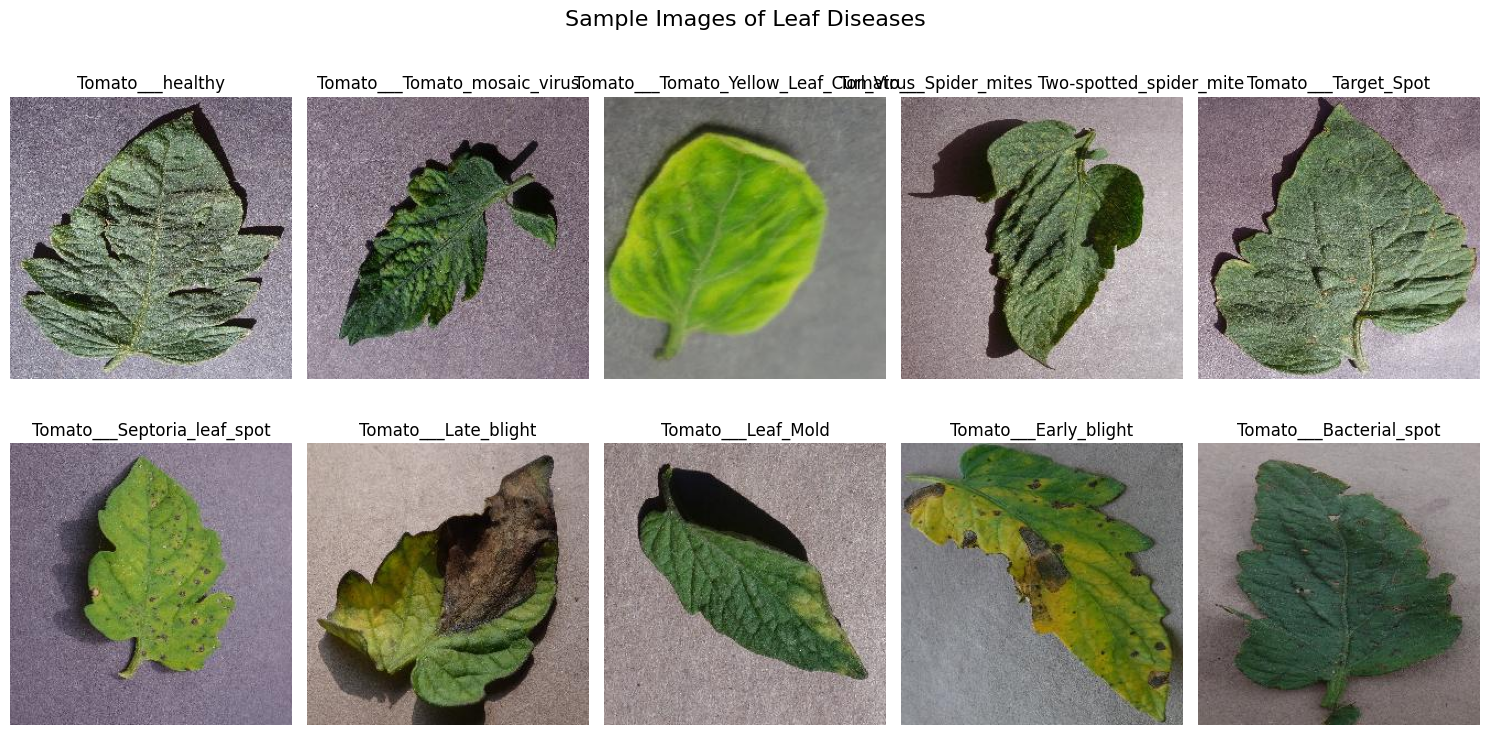

Found 18345 training images
Found 4585 validation images
Number of classes: 10


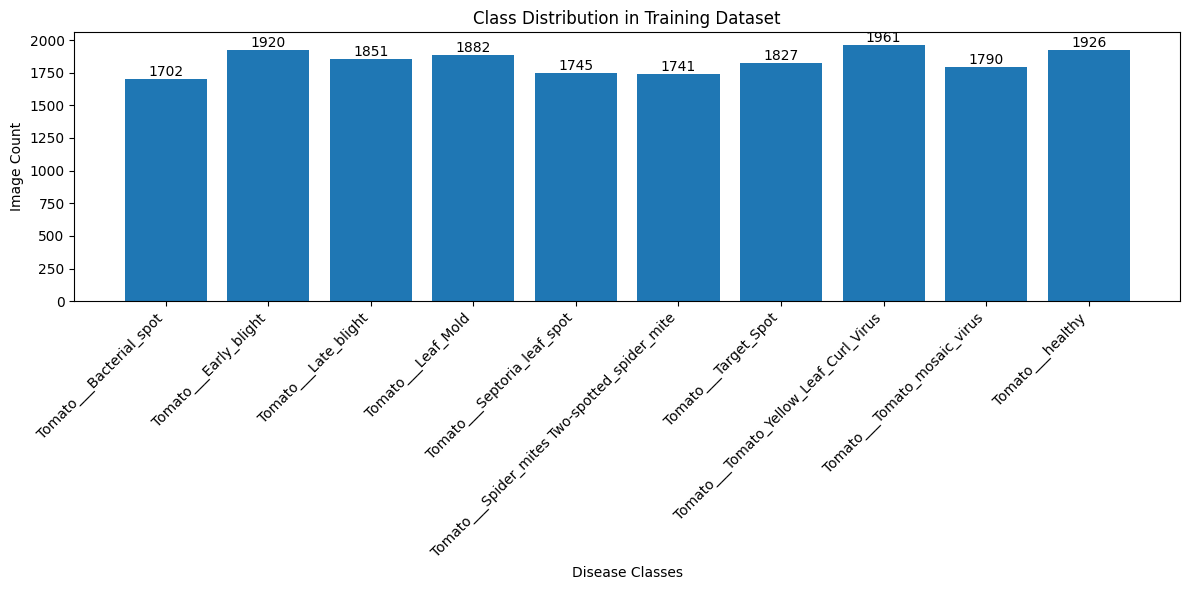

Starting Tomato Leaf Disease Classification with Vision Transformer...
Using device: cpu
Number of classes: 10

Creating Vision Transformer model using timm...
✓ Successfully created ViT model with 10 classes!
✓ Model is on device: cpu

No saved model found. Training new model...

Training Vision Transformer model...


Epoch 1/30 [Train]:   2%|▏         | 11/574 [04:04<3:28:20, 22.20s/it, loss=2.4423, acc=14.77%]


KeyboardInterrupt: 

In [2]:
!pip install -q --upgrade pip
!pip install -q torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu121
!pip install -q timm
!pip install -q --upgrade scikit-learn
!pip install -q --upgrade torch-geometric
!pip install -q tqdm


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import os
import random
import time
import gc
from tqdm import tqdm
from PIL import Image

random.seed(42)
np.random.seed(42)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim import Adam
from torch.utils.data import DataLoader
from torchvision import transforms, datasets
import timm
from torch_geometric.nn import GCNConv

from sklearn.metrics import (
    classification_report, confusion_matrix, accuracy_score,
    precision_score, recall_score, f1_score, matthews_corrcoef,
    ConfusionMatrixDisplay
)
from sklearn.neighbors import KNeighborsClassifier, NearestNeighbors
from sklearn.preprocessing import StandardScaler


torch.manual_seed(42)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(42)
    TORCH_DEVICE = torch.device('cuda')
    print(f'PyTorch version: {torch.__version__}')
    print(f'PyTorch using CUDA: {torch.cuda.get_device_name(0)}')
else:
    TORCH_DEVICE = torch.device('cpu')
    print(f'PyTorch version: {torch.__version__}')
    print('PyTorch using CPU')

print('✓ All imports successful')







from google.colab import drive
drive.mount('/content/drive')

train_path = '/content/drive/MyDrive/Colab Notebooks/Sarif-vai/New Plant Diseases Dataset(Augmented)/train'
test_path = '/content/drive/MyDrive/Colab Notebooks/Sarif-vai/New Plant Diseases Dataset(Augmented)/valid'

if not os.path.exists(train_path):
    print(f"Warning: Training path {train_path} does not exist.")
    print("Please update the paths or upload your dataset to Google Colab.")


if not os.path.exists(test_path):
    print(f"Warning: Test path {test_path} does not exist.")
    print("Please update the paths or upload your dataset to Google Colab.")

def display_sample_images(path):
    if os.path.exists(path):
        disease_list = [d for d in os.listdir(path) if os.path.isdir(os.path.join(path, d))]
        if len(disease_list) > 0:
            fig, axes = plt.subplots(2, 5, figsize=(15, 8))
            fig.suptitle('Sample Images of Leaf Diseases', fontsize=16)
            for i, disease in enumerate(disease_list[:10]):
                disease_path = os.path.join(path, disease)
                if os.path.exists(disease_path):
                    images = [f for f in os.listdir(disease_path) if f.lower().endswith(('.png', '.jpg', '.jpeg'))]
                    if images:
                        sample_image = random.choice(images)
                        img = Image.open(os.path.join(disease_path, sample_image))
                        row, col = i // 5, i % 5
                        if row < 2 and col < 5:
                            axes[row, col].imshow(img)
                            axes[row, col].set_title(disease, fontsize=12)
                            axes[row, col].axis('off')
            for i in range(len(disease_list), 10):
                row, col = i // 5, i % 5
                if row < 2 and col < 5:
                    axes[row, col].axis('off')

            plt.tight_layout()
            plt.show()
    else:
        print(f"Path {path} not found. Skipping image display.")


display_sample_images(train_path)


IMAGE_SIZE = 224
BATCH_SIZE = 32


train_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomRotation(15),
    transforms.ColorJitter(brightness=0.2, contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])


test_transform = transforms.Compose([
    transforms.Resize((IMAGE_SIZE, IMAGE_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(mean=[0.5, 0.5, 0.5], std=[0.5, 0.5, 0.5])
])


def create_data_loaders():
    try:
        train_dataset = datasets.ImageFolder(root=train_path, transform=train_transform)
        test_dataset = datasets.ImageFolder(root=test_path, transform=test_transform)

        train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True, num_workers=2)
        test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False, num_workers=2)

        print(f"Found {len(train_dataset)} training images")
        print(f"Found {len(test_dataset)} validation images")
        print(f"Number of classes: {len(train_dataset.classes)}")

        return train_loader, test_loader, train_dataset, test_dataset
    except Exception as e:
        print(f"Error loading datasets: {e}")
        return None, None, None, None

train_loader, test_loader, train_dataset, test_dataset = create_data_loaders()

def display_class_distribution(dataset):
    if dataset is not None:

        disease_classes = dataset.classes
        class_counts = []

        for class_name in disease_classes:
            class_dir = os.path.join(train_path, class_name)
            if os.path.exists(class_dir):
                num_images = len([f for f in os.listdir(class_dir)
                                if f.lower().endswith(('.png', '.jpg', '.jpeg'))])
                class_counts.append(num_images)
            else:
                class_counts.append(0)

        plt.figure(figsize=(12, 6))
        bars = plt.bar(range(len(disease_classes)), class_counts)
        plt.title('Class Distribution in Training Dataset')
        plt.xlabel('Disease Classes')
        plt.ylabel('Image Count')
        plt.xticks(range(len(disease_classes)), disease_classes, rotation=45, ha='right')


        for bar, count in zip(bars, class_counts):
            plt.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.01,
                    str(count), ha='center', va='bottom')

        plt.tight_layout()
        plt.show()
    else:
        print("No training data available for class distribution plot.")

display_class_distribution(train_dataset)


def get_features_pytorch(loader, feature_extractor, device):
    features = []
    labels = []

    feature_extractor.eval()
    print("Extracting features...")

    with torch.no_grad():
        for i, (images, targets) in enumerate(tqdm(loader, desc="Feature extraction")):
            images = images.to(device)

            batch_features = feature_extractor(images)
            features.append(batch_features.cpu().numpy())
            labels.append(targets.numpy())


            if i % 50 == 0:
                gc.collect()

    return np.vstack(features), np.concatenate(labels)

class SimpleGNN(torch.nn.Module):
    def __init__(self, num_features, hidden_dim, num_classes):
        super(SimpleGNN, self).__init__()
        self.conv1 = GCNConv(num_features, hidden_dim)
        self.conv2 = GCNConv(hidden_dim, num_classes)
        self.dropout = 0.5

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = F.relu(x)
        x = F.dropout(x, training=self.training, p=self.dropout)
        x = self.conv2(x, edge_index)
        return F.log_softmax(x, dim=1)

def create_graph(features, k=5):
    nbrs = NearestNeighbors(n_neighbors=k+1).fit(features)
    distances, indices = nbrs.kneighbors(features)


    indices = indices[:, 1:]

    sources = np.repeat(np.arange(len(features)), k)
    targets = indices.flatten()
    edge_index = torch.tensor(np.vstack([sources, targets]), dtype=torch.long)

    return edge_index


def create_vit_model(num_classes):
    print("\n" + "="*60)
    print("Creating Vision Transformer model using timm...")

    try:

        model = timm.create_model(
            'vit_base_patch16_224',
            pretrained=True,
            num_classes=num_classes
        )


        for name, param in model.named_parameters():
            if 'head' not in name:
                param.requires_grad = False


        model = model.to(TORCH_DEVICE)

        print(f"✓ Successfully created ViT model with {num_classes} classes!")
        print(f"✓ Model is on device: {TORCH_DEVICE}")
        print("="*60 + "\n")

        return model

    except Exception as e:
        print(f"✗ Error creating ViT model: {e}")
        raise e


def train_model_pytorch(model, train_loader, test_loader, num_epochs=30, lr=1e-4):
    print("\nTraining Vision Transformer model...")


    criterion = nn.CrossEntropyLoss()
    optimizer = torch.optim.Adam(filter(lambda p: p.requires_grad, model.parameters()), lr=lr)


    scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer, mode='min', factor=0.2, patience=3, min_lr=1e-6
    )


    history = {'train_loss': [], 'train_acc': [], 'val_loss': [], 'val_acc': []}
    best_val_acc = 0.0
    patience_counter = 0
    max_patience = 5

    for epoch in range(num_epochs):

        model.train()
        train_loss = 0.0
        train_correct = 0
        train_total = 0

        train_pbar = tqdm(train_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Train]")
        for images, labels in train_pbar:
            images, labels = images.to(TORCH_DEVICE), labels.to(TORCH_DEVICE)


            optimizer.zero_grad()
            outputs = model(images)
            loss = criterion(outputs, labels)


            loss.backward()
            optimizer.step()


            train_loss += loss.item()
            _, predicted = torch.max(outputs.data, 1)
            train_total += labels.size(0)
            train_correct += (predicted == labels).sum().item()

            train_pbar.set_postfix({'loss': f'{loss.item():.4f}',
                                   'acc': f'{100 * train_correct / train_total:.2f}%'})

        train_loss = train_loss / len(train_loader)
        train_acc = 100 * train_correct / train_total


        model.eval()
        val_loss = 0.0
        val_correct = 0
        val_total = 0

        with torch.no_grad():
            val_pbar = tqdm(test_loader, desc=f"Epoch {epoch+1}/{num_epochs} [Val]")
            for images, labels in val_pbar:
                images, labels = images.to(TORCH_DEVICE), labels.to(TORCH_DEVICE)

                outputs = model(images)
                loss = criterion(outputs, labels)

                val_loss += loss.item()
                _, predicted = torch.max(outputs.data, 1)
                val_total += labels.size(0)
                val_correct += (predicted == labels).sum().item()

                val_pbar.set_postfix({'loss': f'{loss.item():.4f}',
                                     'acc': f'{100 * val_correct / val_total:.2f}%'})

        val_loss = val_loss / len(test_loader)
        val_acc = 100 * val_correct / val_total


        history['train_loss'].append(train_loss)
        history['train_acc'].append(train_acc)
        history['val_loss'].append(val_loss)
        history['val_acc'].append(val_acc)

        print(f"\nEpoch {epoch+1}/{num_epochs}:")
        print(f"Train Loss: {train_loss:.4f}, Train Acc: {train_acc:.2f}%")
        print(f"Val Loss: {val_loss:.4f}, Val Acc: {val_acc:.2f}%")


        scheduler.step(val_loss)


        if val_acc > best_val_acc:
            best_val_acc = val_acc
            patience_counter = 0

            torch.save(model.state_dict(), 'vit_leaf_classifier_best.pth')
            print(f"✓ Saved best model (val_acc: {val_acc:.2f}%)")
        else:
            patience_counter += 1
            if patience_counter >= max_patience:
                print(f"\nEarly stopping triggered after {epoch+1} epochs")
                break


    model.load_state_dict(torch.load('vit_leaf_classifier_best.pth'))
    print("\n✓ Training completed! Loaded best model.")

    return history

def evaluate_model_pytorch(model, test_loader, class_names, model_name="Model"):
    print(f"\nEvaluating {model_name}...")

    model.eval()
    all_predictions = []
    all_true_labels = []

    with torch.no_grad():
        for images, labels in tqdm(test_loader, desc="Evaluating"):
            images = images.to(TORCH_DEVICE)
            outputs = model(images)
            _, predicted = torch.max(outputs.data, 1)

            all_predictions.extend(predicted.cpu().numpy())
            all_true_labels.extend(labels.numpy())

    all_predictions = np.array(all_predictions)
    all_true_labels = np.array(all_true_labels)


    print(f'\n{model_name} Classification Report:')
    print(classification_report(all_true_labels, all_predictions, target_names=class_names))


    conf_matrix = confusion_matrix(all_true_labels, all_predictions)
    plt.figure(figsize=(10, 8))
    sns.heatmap(conf_matrix, annot=True, fmt='d', cmap='Blues',
                xticklabels=class_names, yticklabels=class_names)
    plt.title(f'{model_name} - Confusion Matrix')
    plt.xlabel('Predicted Classes')
    plt.ylabel('True Classes')
    plt.xticks(rotation=45, ha='right')
    plt.yticks(rotation=0)
    plt.tight_layout()
    plt.show()


    metrics = {
        'Accuracy': accuracy_score(all_true_labels, all_predictions),
        'Precision': precision_score(all_true_labels, all_predictions, average='weighted', zero_division=0),
        'Recall': recall_score(all_true_labels, all_predictions, average='weighted', zero_division=0),
        'F1 Score': f1_score(all_true_labels, all_predictions, average='weighted', zero_division=0),
        'MCC': matthews_corrcoef(all_true_labels, all_predictions)
    }

    print(f"\n{model_name} Performance Metrics:")
    for metric, value in metrics.items():
        print(f"{metric}: {value:.4f}")

    return metrics

def main():
    global vit_classifier, scaler, knn, gnn_model, edge_index

    if train_loader is None or test_loader is None:
        print("Cannot proceed without dataset. Please check your dataset paths.")
        return

    num_classes = len(train_dataset.classes)
    class_names = train_dataset.classes
    print(f"Number of classes: {num_classes}")


    try:
        vit_classifier = create_vit_model(num_classes)

        if os.path.exists('vit_leaf_classifier_best.pth'):
            vit_classifier.load_state_dict(torch.load('vit_leaf_classifier_best.pth'))
            print("✓ Loaded pretrained Vision Transformer model.")
        else:
            print("No saved model found. Training new model...")


            start_time = time.time()
            history = train_model_pytorch(vit_classifier, train_loader, test_loader, num_epochs=30, lr=1e-4)
            training_time = time.time() - start_time
            print(f"Training completed in {training_time:.2f} seconds")


            plt.figure(figsize=(12, 5))
            plt.subplot(1, 2, 1)
            plt.plot(history['train_acc'], label='Train Accuracy')
            plt.plot(history['val_acc'], label='Validation Accuracy')
            plt.title('Accuracy Over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel('Accuracy (%)')
            plt.legend()

            plt.subplot(1, 2, 2)
            plt.plot(history['train_loss'], label='Train Loss')
            plt.plot(history['val_loss'], label='Validation Loss')
            plt.title('Loss Over Epochs')
            plt.xlabel('Epochs')
            plt.ylabel('Loss')
            plt.legend()

            plt.tight_layout()
            plt.show()

    except Exception as e:
        print(f"Error in model creation/loading: {e}")
        return


    print("Setting up feature extractor...")
    class FeatureExtractor(nn.Module):
        def __init__(self, base_model):
            super().__init__()
            self.base_model = base_model

        def forward(self, x):

            features = self.base_model.forward_features(x)

            features = features.mean(dim=1)
            return features

    feature_extractor = FeatureExtractor(vit_classifier).to(TORCH_DEVICE)
    feature_extractor.eval()


    train_features, train_labels = get_features_pytorch(train_loader, feature_extractor, TORCH_DEVICE)
    test_features, test_labels = get_features_pytorch(test_loader, feature_extractor, TORCH_DEVICE)


    print("Scaling features...")
    scaler = StandardScaler()
    train_features_scaled = scaler.fit_transform(train_features)
    test_features_scaled = scaler.transform(test_features)


    print("Training KNN classifier...")
    knn = KNeighborsClassifier(n_neighbors=5, weights='distance')
    knn.fit(train_features_scaled, train_labels)


    print("Creating and training GNN...")
    edge_index = create_graph(train_features_scaled, k=5)
    gnn_model = SimpleGNN(
        num_features=train_features_scaled.shape[1],
        hidden_dim=64,
        num_classes=num_classes
    ).to(TORCH_DEVICE)

    optimizer = torch.optim.Adam(gnn_model.parameters(), lr=0.01)


    gnn_model.train()
    for epoch in range(100):
        optimizer.zero_grad()
        out = gnn_model(
            torch.as_tensor(train_features_scaled, dtype=torch.float32, device=TORCH_DEVICE),
            edge_index.to(TORCH_DEVICE)
        )
        loss = F.nll_loss(
            out,
            torch.as_tensor(train_labels, dtype=torch.long, device=TORCH_DEVICE)
        )
        loss.backward()
        optimizer.step()

        if epoch % 20 == 0:
            print(f'GNN Epoch {epoch}, Loss: {loss.item():.4f}')


    def hybrid_predict(image_tensor):
        vit_classifier.eval()
        with torch.no_grad():
            if len(image_tensor.shape) == 3:
                image_tensor = image_tensor.unsqueeze(0)
            image_tensor = image_tensor.to(TORCH_DEVICE)
            vit_out = vit_classifier(image_tensor)
            vit_pred = torch.softmax(vit_out, dim=1).cpu().numpy()


        with torch.no_grad():
            features = feature_extractor(image_tensor).cpu().numpy().astype(np.float32)
        features_scaled = scaler.transform(features).astype(np.float32)


        knn_pred = knn.predict_proba(features_scaled)


        with torch.no_grad():
            gnn_model.eval()
            single_edge_index = torch.tensor([[0], [0]], dtype=torch.long, device=TORCH_DEVICE)
            gnn_out = gnn_model(
                torch.as_tensor(features_scaled, dtype=torch.float32, device=TORCH_DEVICE),
                single_edge_index
            )
            gnn_pred = torch.exp(gnn_out).cpu().numpy()

        vit_conf = np.max(vit_pred)
        knn_conf = np.max(knn_pred)
        gnn_conf = np.max(gnn_pred)


        final_pred = 0.7 * vit_pred + 0.2 * knn_pred + 0.1 * gnn_pred
        return final_pred


    print("\n" + "="*50)
    print("MODEL EVALUATION")
    print("="*50)


    vit_metrics = evaluate_model_pytorch(vit_classifier, test_loader, class_names, "Vision Transformer")


    print("\n⚠️ Note: Hybrid model evaluation requires individual image processing")
    print("For full hybrid evaluation, implement batch-wise hybrid predictions")

    print("\n" + "="*50)
    print("EVALUATION COMPLETE")
    print("="*50)
    print(f"\n✓ Vision Transformer model trained and evaluated successfully!")
    print(f"✓ Model saved as 'vit_leaf_classifier_best.pth'")
    print(f"✓ All visualizations generated")

if __name__ == "__main__":
    print("Starting Tomato Leaf Disease Classification with Vision Transformer...")
    print(f"Using device: {TORCH_DEVICE}")
    print("="*60)

    main()